# Fragrance Market Exploration

**Author:** Charlotte Zhu

![cover](../figures/cover.jpeg)

## I. Introduction

The "lipstick effect" describes how sales of small, affordable luxuries hold up or rise during a recession while
overall spending falls. In 2024, overall beauty growth slowed, but fragrance stood out. Euromonitor estimates the
global fragrance market at about **$60B in 2024**, and Estée Lauder, L'Oréal and LVMH all reported fragrance as their
most dynamic premium segment.

This notebook looks at the "olfactory economy" from three angles:

1. **Market trends**: How has the number of perfume launches changed over time, and how has the concentration mix (EDP / EDT / EDC) shifted?
2. **Brand strategy**: How do leading brands position themselves on e-commerce (assortment breadth, price, gender focus)?
3. **Product accords**:
   - *Demand side*: How do consumers rate different accords?
   - *Supply side*: Which accords do brands tend to combine?

## II. Data

Both datasets come from Kaggle.

| Dataset | Source | Rows | Content |
|---|---|---|---|
| `parfumo.csv` | Scraped from [Parfumo](https://www.parfumo.com/), a fragrance community (Sep 2024) | 59,315 | Name, brand, release year, concentration, main accords, notes, rating |
| `ebay_women.csv`, `ebay_men.csv` | Scraped from [eBay](https://www.ebay.com/) listings (Jun 2024) | 1,000 + 1,000 | Brand, type, price, units sold, stock, location |

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import networkx as nx
import numpy as np
import pandas as pd
from adjustText import adjust_text

warnings.filterwarnings("ignore")

DATA = Path("../data")
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

# Colour palette used throughout the report
PINK_LIGHT, PINK, PINK_DARK = "#FFD1DC", "#FFB6C1", "#DB7093"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
})

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

In [2]:
perfumes = pd.read_csv(DATA / "parfumo.csv", dtype=str)
perfumes = perfumes[perfumes["Name"] != "Name"]          # drop repeated header rows (dirty data)
perfumes = perfumes.replace("N/A", np.nan)

perfumes["Release Year"] = pd.to_numeric(perfumes["Release Year"], errors="coerce")
perfumes["Rating Value"] = pd.to_numeric(perfumes["Rating Value"], errors="coerce")
perfumes["Rating Count"] = (
    perfumes["Rating Count"].fillna("0").str.replace(r"\D", "", regex=True).replace("", "0").astype(int)
)

sales_w = pd.read_csv(DATA / "ebay_women.csv").assign(female_flag=1)
sales_m = pd.read_csv(DATA / "ebay_men.csv").assign(female_flag=0)

print(f"Parfumo: {perfumes.shape[0]:,} perfumes | eBay: {len(sales_w):,} women's + {len(sales_m):,} men's listings")
perfumes.head(3)

Parfumo: 59,315 perfumes | eBay: 1,000 women's + 1,000 men's listings


,Name,Brand,Release Year,Concentration,Rating Value,Rating Count,Main Accords,Top Notes,Middle Notes,Base Notes,Perfumers,URL
0,# 455 Tabac Écarlate Le Ré Noir,Le Ré Noir,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,Valery Sokolov / Валерий Соколов,https://www.parfumo.com/Perfumes/Le_Re_Noir/45...
1,#0071 Tidal Pool CB I Hate Perfume 2004,CB I Hate Perfume,2004.0,NaN,NaN,0,NaN,Bergamot,French lavender,"Musk, Foulness",Harry Frémont,https://www.parfumo.com/Perfumes/CB_I_Hate_Per...
2,#0154 Pumpkin Pie CB I Hate Perfume 1998,CB I Hate Perfume,1998.0,NaN,NaN,0,"Green, Leathery, Chypre, Animal",NaN,NaN,NaN,NaN,https://www.parfumo.com/Perfumes/CB_I_Hate_Per...


## III. Analysis

### 1. Market Trend Analysis

Looking at perfumes released since 1900: **launches were few and stable in the first half of the 20th century, grew
quickly from the 1980s, accelerated after 2010, peaked in 2015–2019, and have declined slightly since.** Bar colour
shows the number of Parfumo ratings. Newer perfumes collect more ratings, which reflects the growth of the internet.

This matches how the industry developed. Early production was slow and the customer base was a small affluent group,
so brands had little reason to launch many products. From the 1980s, rising incomes widened demand and brands invested
in R&D and new launches. The recent decline is consistent with market saturation and with brands becoming more
cautious after the pandemic.

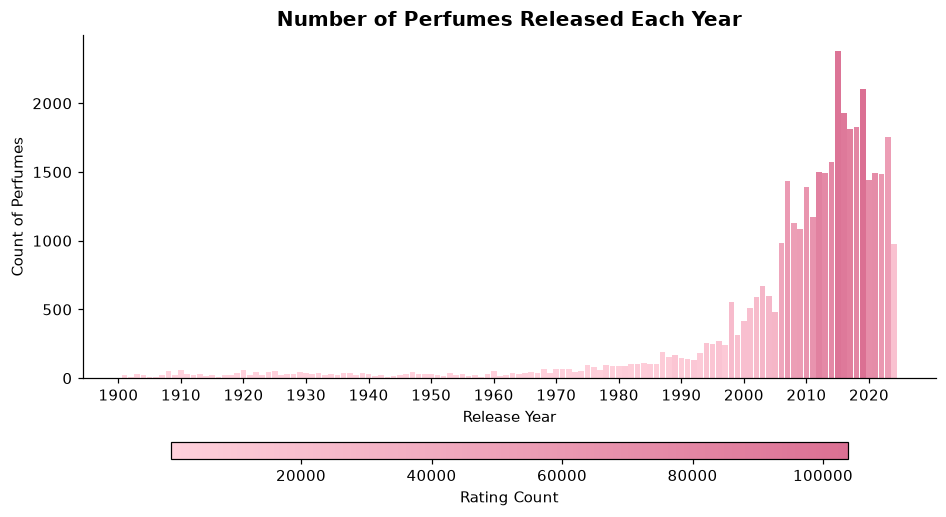

In [3]:
year_summary = (
    perfumes[perfumes["Release Year"] > 1900]
    .groupby("Release Year")
    .agg(perfume_count=("Name", "size"), rating_count=("Rating Count", "sum"))
    .reset_index()
)

cmap = mcolors.LinearSegmentedColormap.from_list("pink", [PINK_LIGHT, PINK_DARK])
norm = mcolors.Normalize(year_summary["rating_count"].min(), year_summary["rating_count"].max())

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(year_summary["Release Year"], year_summary["perfume_count"],
       color=cmap(norm(year_summary["rating_count"])), width=0.9)
ax.set(title="Number of Perfumes Released Each Year", xlabel="Release Year", ylabel="Count of Perfumes")
ax.set_xticks(range(1900, 2030, 10))
cbar = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, orientation="horizontal",
                    pad=0.15, fraction=0.04, aspect=40)
cbar.set_label("Rating Count")
save(fig, "01_releases_by_year")
plt.show()

Next, for perfumes launched since 1971, the chart shows the yearly mix of concentrations (EDP > EDT > EDC, from
strongest to lightest). **EDP started with a small share but grew steadily and now leads the market. EDT stayed fairly
stable and has dipped slightly in recent years. EDC was common early on and has declined overall.**

One likely reason is that consumers now look for scents that feel unique and personal. EDP is more intense and lasts
longer, so it suits both everyday wear and special occasions.

*Parfumo's concentration labels are very detailed, so I grouped them into EDP / EDT / EDC by text matching.*

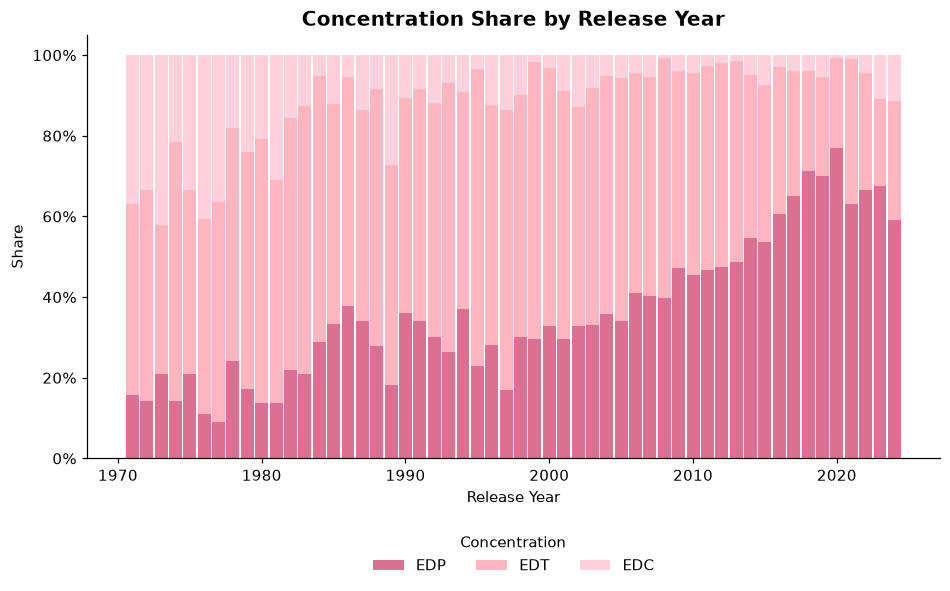

In [4]:
def classify_concentration(s: pd.Series) -> pd.Series:
    s = s.str.lower()
    return np.select(
        [s.str.contains("eau de toilette"), s.str.contains("eau de parfum"), s.str.contains("cologne")],
        ["EDT", "EDP", "EDC"],
        default="Other",
    )

conc = perfumes[(perfumes["Release Year"] > 1970) & perfumes["Concentration"].notna()].copy()
conc["concentration_group"] = classify_concentration(conc["Concentration"])

share = (
    conc[conc["concentration_group"] != "Other"]
    .groupby(["Release Year", "concentration_group"]).size()
    .unstack(fill_value=0)[["EDP", "EDT", "EDC"]]
)
share = share.div(share.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, 5))
bottom = np.zeros(len(share))
for col, colour in zip(["EDP", "EDT", "EDC"], [PINK_DARK, PINK, PINK_LIGHT]):
    ax.bar(share.index, share[col], bottom=bottom, color=colour, label=col, width=0.9)
    bottom += share[col].values
ax.set(title="Concentration Share by Release Year", xlabel="Release Year", ylabel="Share")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(title="Concentration", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
save(fig, "02_concentration_share")
plt.show()

### 2. Brand Strategy Analysis

The bubble chart compares the **top 10 brands on eBay (2024) by sales revenue** (price × units sold), using only
EDT/EDP listings that have a price and at least one sale:

- **x-axis**: number of listed products (assortment breadth)
- **y-axis**: average price (USD)
- **colour**: *Female Dominance Index*, the share of a brand's listings that are women's fragrances
- **bubble size**: sales revenue

In [5]:
combined = pd.concat([sales_w, sales_m], ignore_index=True)
combined = combined[
    (combined["price"] != 0) & (combined["sold"] != 0)
    & combined["type"].isin(["Eau de Toilette", "Eau de Parfum"])
]

brands = (
    combined.assign(revenue=combined["price"] * combined["sold"])
    .groupby("brand")
    .agg(num_perfumes=("title", "size"),
         total_sales=("revenue", "sum"),
         avg_price=("price", "mean"),
         female_share=("female_flag", "mean"))     # Female Dominance Index
    .nlargest(10, "total_sales")
    .reset_index()
)
brands

,brand,num_perfumes,total_sales,avg_price,female_share
0,Versace,48,4399906.31,35.958750,0.604167
1,Calvin Klein,28,2291814.88,25.195714,0.500000
2,Davidoff,10,1682428.47,25.608000,0.400000
3,Azzaro,13,1586654.21,39.081538,0.000000
4,Burberry,30,1215257.08,38.193667,0.633333
5,Paco Rabanne,38,1061636.68,59.004474,0.052632
6,Yves Saint Laurent,44,930642.58,60.051818,0.500000
7,Ralph Lauren,46,916125.95,38.416304,0.173913
8,Dolce & Gabbana,13,891572.84,32.900000,0.692308
9,Armaf,33,870964.76,37.496667,0.151515


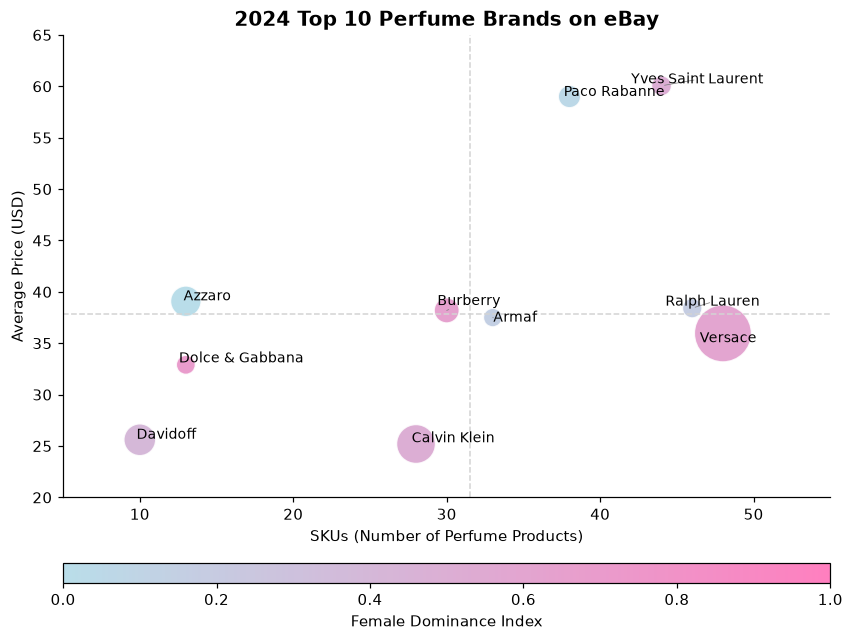

,brand,quadrant,num_perfumes,avg_price,female_share
3,Azzaro,Few products / High price,13,39.08,0.00
4,Burberry,Few products / High price,30,38.19,0.63
1,Calvin Klein,Few products / Low price,28,25.20,0.50
2,Davidoff,Few products / Low price,10,25.61,0.40
8,Dolce & Gabbana,Few products / Low price,13,32.90,0.69
5,Paco Rabanne,Many products / High price,38,59.00,0.05
6,Yves Saint Laurent,Many products / High price,44,60.05,0.50
7,Ralph Lauren,Many products / High price,46,38.42,0.17
0,Versace,Many products / Low price,48,35.96,0.60
9,Armaf,Many products / Low price,33,37.50,0.15


In [6]:
sizes = np.interp(brands["total_sales"], (brands["total_sales"].min(), brands["total_sales"].max()), (150, 1400))
gender_cmap = mcolors.LinearSegmentedColormap.from_list("gender", ["lightblue", "hotpink"])

fig, ax = plt.subplots(figsize=(9, 6.5))
sc = ax.scatter(brands["num_perfumes"], brands["avg_price"], s=sizes, c=brands["female_share"],
                cmap=gender_cmap, vmin=0, vmax=1, alpha=0.85, edgecolor="white", linewidth=1)
texts = [ax.text(x, y, b, fontsize=9) for x, y, b in
         zip(brands["num_perfumes"], brands["avg_price"], brands["brand"])]
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))

# Quadrant guides at the median of each axis
ax.axvline(brands["num_perfumes"].median(), color="lightgray", ls="--", lw=1)
ax.axhline(brands["avg_price"].median(), color="lightgray", ls="--", lw=1)

ax.set(title="2024 Top 10 Perfume Brands on eBay", xlabel="SKUs (Number of Perfume Products)",
       ylabel="Average Price (USD)", xlim=(5, 55), ylim=(20, 65))
cbar = fig.colorbar(sc, ax=ax, orientation="horizontal", pad=0.12, fraction=0.04, aspect=40)
cbar.set_label("Female Dominance Index")
save(fig, "03_brand_positioning")
plt.show()

x_mid, y_mid = brands["num_perfumes"].median(), brands["avg_price"].median()
brands["quadrant"] = (
    np.where(brands["num_perfumes"] >= x_mid, "Many products", "Few products") + " / "
    + np.where(brands["avg_price"] >= y_mid, "High price", "Low price")
)
brands.sort_values("quadrant")[["brand", "quadrant", "num_perfumes", "avg_price", "female_share"]].round(2)

Brands choose different e-commerce strategies depending on their positioning, target customers and competition. Splitting the chart into quadrants:

| Quadrant | Representative brands | Strategy |
|---|---|---|
| **Few products, low price** | Davidoff, Calvin Klein, Dolce & Gabbana | A small range of signature scents at accessible prices. Keeps operations lean and targets price-sensitive, younger mass-market customers. |
| **Few products, high price** | Azzaro, Burberry | A boutique approach: a few distinctive scents and a strong brand story for customers who pay for identity and uniqueness. |
| **Many products, high price** | Yves Saint Laurent, Paco Rabanne, Ralph Lauren | A broad range that stays premium. Covers many preferences while keeping a high-end image. YSL and Paco Rabanne sit well above the rest, at about $60 on average. |
| **Many products, low price** | Versace, Armaf | A wide assortment at good value. Versace pairs the largest catalogue with mid-range prices and has the **highest revenue in the sample** by a wide margin. |

**Gender positioning:** Dolce & Gabbana (69% women's listings), Burberry and Versace lean female. Azzaro (0%),
Paco Rabanne (5%), Armaf and Ralph Lauren lean male. Across the top 10, the women's share averages about 40%, so the
leading brands are fairly balanced. This goes against the idea that perfume is a female-dominated category and fits
the shift toward **gender-fluid, unisex positioning**.

*Note: this eBay sample covers only 2,000 listings, so these 10 brands may not be eBay's actual top sellers. The
differences in strategy are still worth comparing.*

### 3. Product Accord Analysis

#### 1) Demand side: how do consumers rate different accords?

Overall ratings are **concentrated in the 6–8 range with a long left tail**. Few perfumes score below 5. Forum users
are generally satisfied, but Parfumo is a "recommendation" community more than a critical-review one, so the ratings
probably carry some **self-selection bias**.

count    30046.00
mean         7.35
std          0.93
min          0.00
25%          6.90
50%          7.40
75%          7.90
max         10.00
variance  0.87


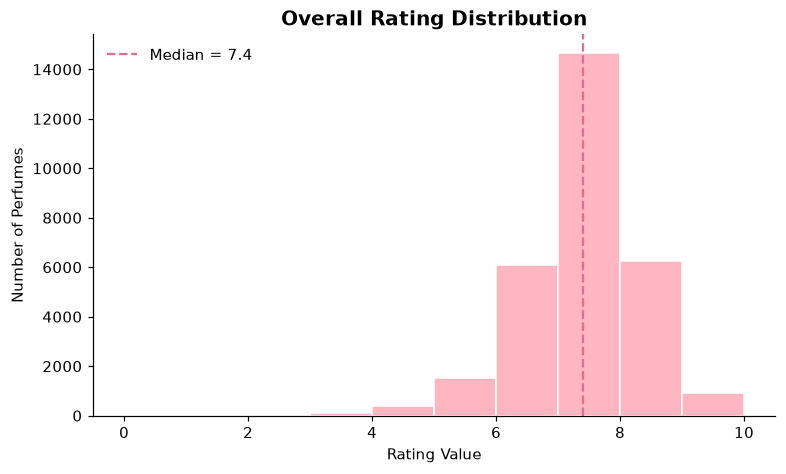

In [7]:
ratings = perfumes["Rating Value"].dropna()
print(ratings.describe().round(2).to_string())
print(f"variance  {ratings.var():.2f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(ratings, bins=np.arange(0, 11, 1), color=PINK, edgecolor="white")
ax.axvline(ratings.median(), color=PINK_DARK, ls="--", lw=1.5, label=f"Median = {ratings.median():.1f}")
ax.set(title="Overall Rating Distribution", xlabel="Rating Value", ylabel="Number of Perfumes")
ax.legend(frameon=False)
save(fig, "04_rating_distribution")
plt.show()

By accord, **most perfumes reach a solid quality bar**. All medians fall between 6.8 and 7.9, and mainstream
accords such as Floral (7.4), Woody (7.5) and Fruity (7.2) sit close together, so consumers broadly agree on what a
well-made perfume is.

Two patterns stand out:

- **Niche, "connoisseur" accords rate highest.** Chypre, Animal, Leathery, Smoky, Resinous and Oriental all have
  medians around 7.8–7.9. These are polarizing styles, so the people who rate them on an enthusiast forum have
  usually already chosen them on purpose.
- **Mass-market fresh accords rate lowest and vary most.** Fresh, Fruity, Aquatic and especially Synthetic (median
  6.8) are at the bottom. Aquatic, Synthetic and Animal also have the widest spread (std ≈ 1.0), while Creamy and
  Resinous ratings are the most consistent (std ≈ 0.7). Aquatic and synthetic notes are hard to make smell natural,
  and imperfect formulas can come across as "chemical", which splits opinion.

*Box width is proportional to √(number of perfumes); whiskers extend to 3 × IQR.*

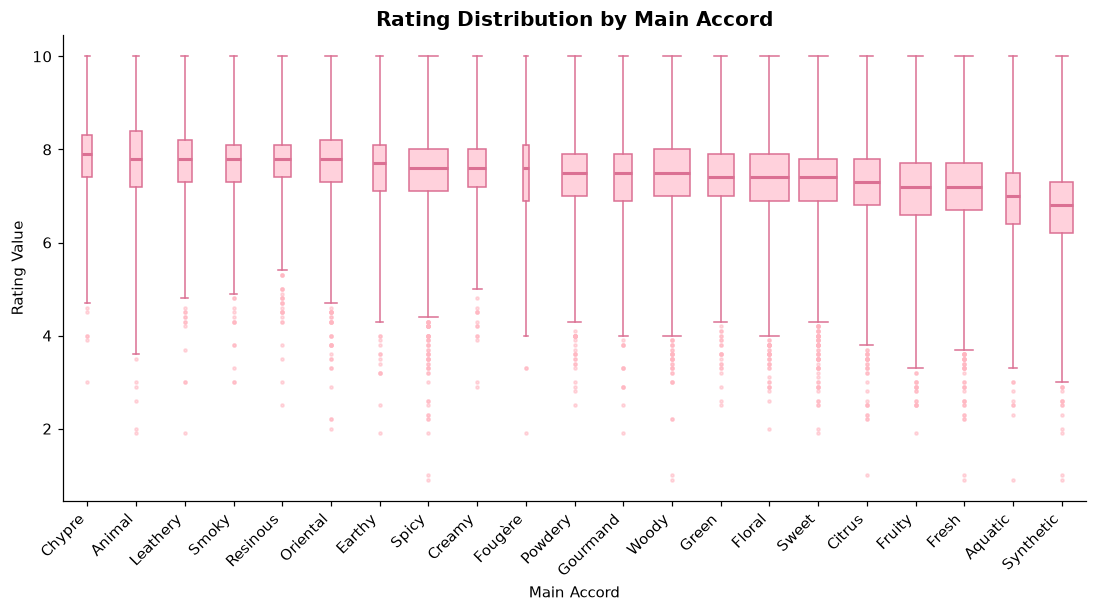

,count,median,std
accord,,,
Creamy,3586,7.6,0.70
Resinous,3127,7.8,0.72
Smoky,2468,7.8,0.75
Leathery,2147,7.8,0.79
Green,7248,7.4,0.81
Spicy,15361,7.6,0.82
Woody,13952,7.5,0.83
Powdery,6374,7.5,0.83
Oriental,5241,7.8,0.83


In [8]:
# One row per (perfume, accord)
accord_long = (
    perfumes[["Name", "Main Accords", "Rating Value", "Release Year"]]
    .dropna(subset=["Main Accords"])
    .assign(accord=lambda d: d["Main Accords"].str.split(","))
    .explode("accord")
    .assign(accord=lambda d: d["accord"].str.strip())
)
rated = accord_long.dropna(subset=["Rating Value"])
order = rated.groupby("accord")["Rating Value"].median().sort_values(ascending=False).index
groups = [rated.loc[rated["accord"] == a, "Rating Value"].values for a in order]
counts = np.array([len(g) for g in groups])

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.boxplot(groups, tick_labels=order, whis=3, widths=0.8 * np.sqrt(counts / counts.max()),
           patch_artist=True,
           boxprops=dict(facecolor=PINK_LIGHT, color=PINK_DARK),
           medianprops=dict(color=PINK_DARK, lw=2),
           whiskerprops=dict(color=PINK_DARK), capprops=dict(color=PINK_DARK),
           flierprops=dict(marker="o", markersize=2, markerfacecolor=PINK, markeredgecolor=PINK, alpha=0.5))
ax.set(title="Rating Distribution by Main Accord", xlabel="Main Accord", ylabel="Rating Value")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
save(fig, "05_rating_by_accord")
plt.show()

rated.groupby("accord")["Rating Value"].agg(["count", "median", "std"]).round(2).sort_values("std")

#### 2) Supply side: which accords do brands combine?

A perfume usually blends several accords. Using **perfumes released in 2024**, I build an accord co-occurrence
network: each node is an accord, and each edge weight is the number of perfumes that contain both accords.

**Core accords.** I iteratively prune nodes whose weighted degree falls below a threshold (a k-core-style filter)
until the graph stops changing. The remaining accords are the ones blended most often with others, so they are the
"workhorses" of perfume composition.

In [9]:
new_perfumes = perfumes[(perfumes["Release Year"] == 2024) & perfumes["Main Accords"].notna()]

# Binary perfume x accord matrix, then co-occurrence = X^T X with a zero diagonal
X = new_perfumes["Main Accords"].str.get_dummies(sep=", ")
X = X.loc[:, X.var() > 0]
counts = X.T.values @ X.values
np.fill_diagonal(counts, 0)
co_occurrence = pd.DataFrame(counts, index=X.columns, columns=X.columns)
print(f"{len(new_perfumes)} perfumes released in 2024, {X.shape[1]} accords")

def core_subgraph(W: pd.DataFrame, min_degree: float = 250) -> pd.DataFrame:
    """Repeatedly drop nodes whose weighted degree is below `min_degree` until stable."""
    while True:
        keep = W.sum(axis=1) >= min_degree
        if keep.all():
            return W
        W = W.loc[keep, keep]

W_core = core_subgraph(co_occurrence)
g_core = nx.from_pandas_adjacency(W_core)
print(f"Core accords ({g_core.number_of_nodes()}): {sorted(g_core.nodes)}")

522 perfumes released in 2024, 21 accords
Core accords (11): ['Citrus', 'Creamy', 'Floral', 'Fresh', 'Fruity', 'Green', 'Powdery', 'Spicy', 'Sweet', 'Synthetic', 'Woody']


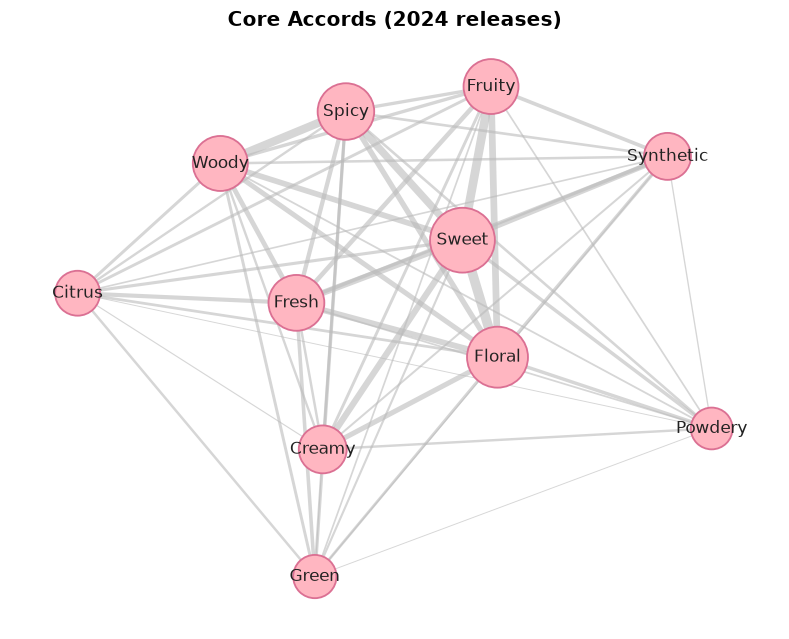

In [10]:
def draw_network(g, ax, node_colors, node_sizes, seed, label_size=11):
    pos = nx.spring_layout(g, weight="weight", seed=seed, k=1.2)
    weights = np.array([d["weight"] for _, _, d in g.edges(data=True)])
    nx.draw_networkx_edges(g, pos, ax=ax, width=0.3 + 6 * weights / weights.max(), edge_color="#BBBBBB", alpha=0.6)
    nx.draw_networkx_nodes(g, pos, ax=ax, node_color=node_colors, node_size=node_sizes,
                           edgecolors=PINK_DARK, linewidths=1.2)
    nx.draw_networkx_labels(g, pos, ax=ax, font_size=label_size, font_color="#222222")
    ax.axis("off")
    return pos

strength = dict(g_core.degree(weight="weight"))
sizes = [300 + 1500 * strength[n] / max(strength.values()) for n in g_core.nodes]

fig, ax = plt.subplots(figsize=(9, 7))
draw_network(g_core, ax, PINK, sizes, seed=35)
ax.set_title("Core Accords (2024 releases)")
save(fig, "06_core_accords")
plt.show()

**Accord communities.** Next, I run **Louvain community detection** on the full co-occurrence network to group
accords that tend to appear together. Intuitively, accords that give a similar sensory impression get blended
together. The three communities are:

In [11]:
g = nx.from_pandas_adjacency(co_occurrence)
communities = nx.community.louvain_communities(g, weight="weight", seed=2001)

# Name each community after a representative "anchor" accord
anchors = {"Woody": "Warm & deep", "Citrus": "Fresh & natural", "Floral": "Sweet & soft"}
community_colors = {"Warm & deep": "#FFE4B5", "Fresh & natural": "#89CFF0", "Sweet & soft": "#F8BBD0"}
named = {}
for c in communities:
    label = next((v for k, v in anchors.items() if k in c), f"Group {len(named) + 1}")
    named[label] = c
for label, c in named.items():
    print(f"{label:<16}: {', '.join(sorted(c))}")
print(f"Modularity: {nx.community.modularity(g, communities, weight='weight'):.3f}")

Fresh & natural : Aquatic, Citrus, Fresh, Green
Warm & deep     : Animal, Chypre, Earthy, Fougère, Leathery, Oriental, Resinous, Smoky, Spicy, Woody
Sweet & soft    : Creamy, Floral, Fruity, Gourmand, Powdery, Sweet, Synthetic
Modularity: 0.093


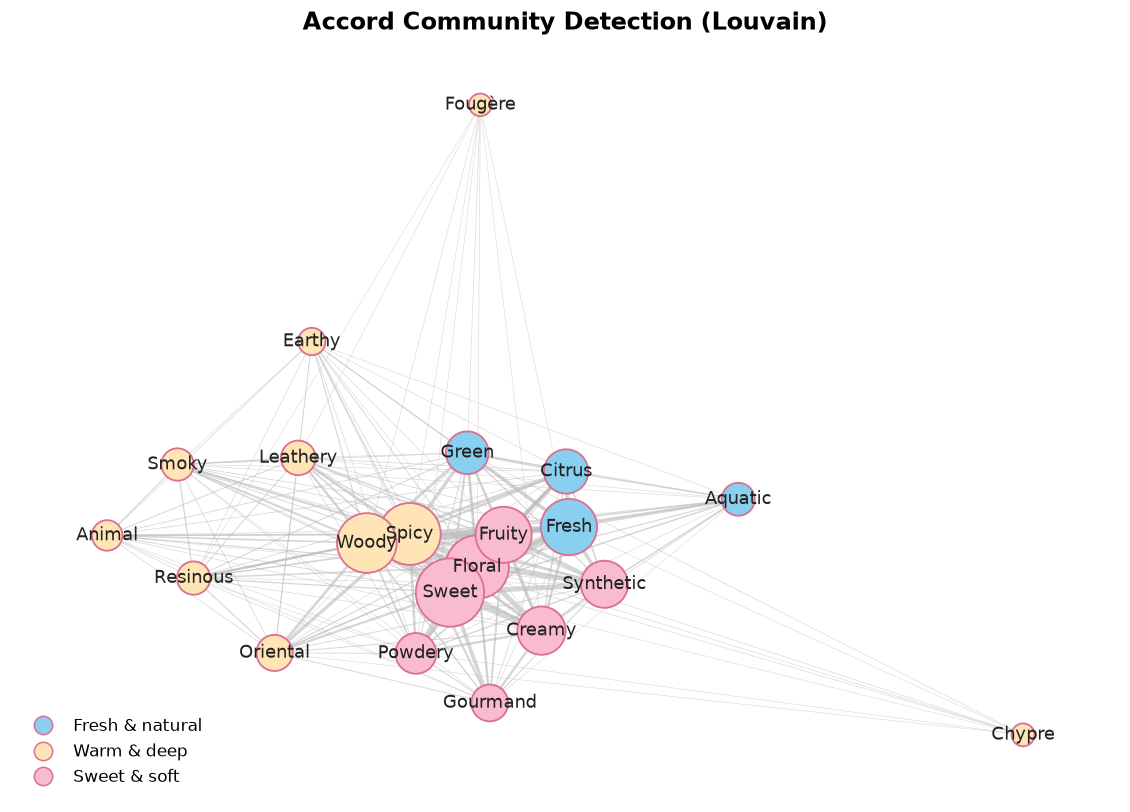

In [12]:
membership = {n: label for label, c in named.items() for n in c}
colors = [community_colors.get(membership[n], "#D7BDE2") for n in g.nodes]
strength = dict(g.degree(weight="weight"))
sizes = [200 + 1800 * strength[n] / max(strength.values()) for n in g.nodes]

fig, ax = plt.subplots(figsize=(13, 9))
draw_network(g, ax, colors, sizes, seed=2001, label_size=12)
handles = [plt.Line2D([], [], marker="o", ls="", markersize=12, markerfacecolor=community_colors.get(lbl, "#D7BDE2"),
                      markeredgecolor=PINK_DARK, label=lbl) for lbl in named]
ax.legend(handles=handles, loc="lower left", frameon=False, fontsize=11)
ax.set_title("Accord Community Detection (Louvain)", fontsize=16)
save(fig, "07_accord_communities")
plt.show()

The three communities correspond to distinct sensory families:

- **Warm & deep** (Woody, Spicy, Oriental, Smoky, Resinous, Leathery, Earthy, Animal, Chypre, Fougère): warm, rich
  and sometimes mysterious, such as sandalwood and cedar, amber and spice, burning wood or resin.
- **Fresh & natural** (Citrus, Fresh, Green, Aquatic): light, airy and clean, like the ocean, lemon peel or fresh-cut
  leaves.
- **Sweet & soft** (Floral, Fruity, Sweet, Creamy, Gourmand, Powdery, Synthetic): sweet and gentle and especially
  popular with female consumers, such as rose, jasmine or ripe fruit.

Accords in the same family give a consistent sensory impression, which makes them natural blending partners.

*Modularity is low (≈ 0.09) because the core accords co-occur with almost everything, so the families overlap
heavily. Louvain is also stochastic: borderline accords such as Spicy or Synthetic can switch families with a
different seed, but the three-family structure is stable.*

## IV. Summary

**1. Market trends.** Fragrance launches grew slowly until the 1980s, accelerated sharply after 2010, peaked in
2015–2019, then declined with market saturation and the pandemic. EDP has become the dominant concentration, which
reflects demand for long-lasting scents that feel personal.

**2. Brand strategy.** Top eBay brands follow four different strategies: lean and affordable, boutique premium, broad
premium, and broad value. Leading brands are fairly balanced by gender, consistent with the shift toward gender-fluid
fragrance.

**3. Accords.**
- *Demand*: Satisfaction is high overall (median 7.4/10). Niche warm accords such as Chypre, Leathery and Resinous
  rate highest. Mass-market fresh and synthetic accords rate lowest, and Aquatic and Synthetic are the most polarizing.
- *Supply*: 11 of 21 accords form the core of 2024 launches (e.g. Floral, Sweet, Woody, Citrus, Fresh).
  Community detection splits accords into **warm & deep**, **fresh & natural** and **sweet & soft** families.

**Implications for brands:** match the e-commerce strategy to the brand's positioning (breadth vs. depth, mass vs.
premium); design for gender-fluid demand; and use accord-pairing patterns to test new combinations, such as fresh ×
woody blends, that offer novelty while staying familiar.